<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_009_SVM_maquinas_de_soporte_vectorial/03_SVM_Kernel_de_Base_Radial_2024_05_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MÁQUINAS DE SOPORTE VECTORIAL - SVM - SUPPORT-VECTOR MACHINES
### Las SVM son separadores no lineales que se construyen a partir de separadores lineales y se generalizan con la aplicación de kernels. Las SVM permiten encontrar límites entre conjuntos que se sobrelapan.

### Las implementaciones presentadas aquí se basan en el capítulo 12 de:

[1]	H. Trevor, T. Robert, y F. JH, The elements of statistical learning: data mining, inference, and prediction. New York, NY: Springer, 2009.

### También es muy buena la descripción presentada en:
https://towardsdatascience.com/understanding-support-vector-machine-part-1-lagrange-multipliers-5c24a52ffc5e
### Y
https://towardsdatascience.com/understanding-support-vector-machine-part-2-kernel-trick-mercers-theorem-e1e6848c6c4d

### Y la clase de MIT-OCW del Dr. Patrick Winston:
https://www.youtube.com/watch?v=_PwhiWxHK8o


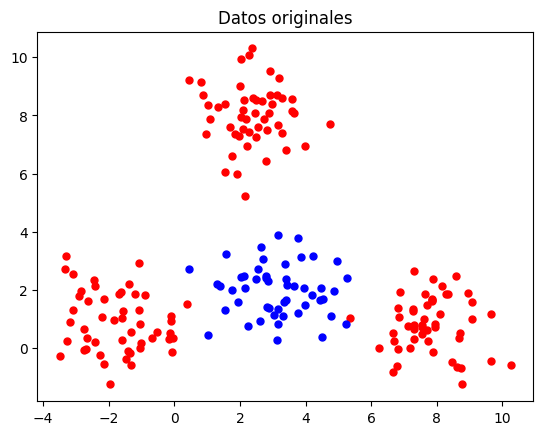

     pcost       dcost       gap    pres   dres
 0: -4.1599e+01 -4.8207e+01  1e+03  2e+01  4e-16
 1: -1.5635e+01 -3.9975e+01  9e+01  1e+00  5e-16
 2: -9.4045e+00 -2.1646e+01  1e+01  7e-15  1e-15
 3: -9.5390e+00 -1.0596e+01  1e+00  1e-15  4e-16
 4: -9.5543e+00 -1.0127e+01  6e-01  2e-15  3e-16
 5: -9.5992e+00 -9.6940e+00  9e-02  7e-16  3e-16
 6: -9.6169e+00 -9.6381e+00  2e-02  2e-16  3e-16
 7: -9.6217e+00 -9.6282e+00  6e-03  3e-15  3e-16
 8: -9.6234e+00 -9.6247e+00  1e-03  3e-15  2e-16
 9: -9.6237e+00 -9.6242e+00  5e-04  2e-15  2e-16
10: -9.6238e+00 -9.6241e+00  2e-04  2e-16  2e-16
11: -9.6239e+00 -9.6240e+00  3e-05  2e-15  2e-16
12: -9.6239e+00 -9.6239e+00  3e-06  3e-16  3e-16
Optimal solution found.


<ipython-input-6-5a2a66994ec4>:91: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yp[i] = np.sign(prediction)


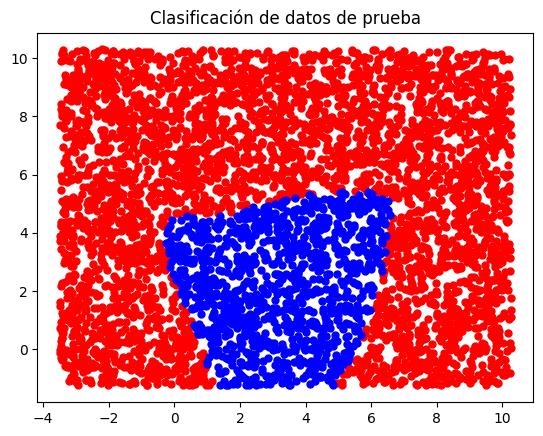

In [ ]:
import numpy as np
from cvxopt import matrix, solvers
import matplotlib.pyplot as plt

def gaussian_kernel(x1, x2, sigma):
    #media = [0, 0]  # Media
    #covarianza = [[sigma, 0], [0, sigma]]  # Matriz de covarianza
    #Z = np.exp(-((X - media[0])**2 / (2 * covarianza[0][0]) + (Y - media[1])**2 / (2 * covarianza[1][1])))
    # Z = np.exp(-((x1[0]-x2[0])**2 / (2 * covarianza[0][0]) + ...
    #             (x1[1]-x2[1])**2 / (2 * covarianza[1][1])))
    # Z /= (2 * np.pi * np.sqrt(np.linalg.det(covarianza)))
    Z = np.exp(-((x1[0]-x2[0])**2 / (2 * sigma) +
                (x1[1]-x2[1])**2 / (2 * sigma)))
    Z /= (2 * np.pi * sigma)
    #return np.exp(-np.linalg.norm(x1-x2)**2 / (2*(sigma**2)))
    return Z

# Generación de datos
n = 50
np.random.seed(0)  # Para reproducibilidad
x11 = np.random.randn(n, 1) + 3
x12 = np.random.randn(n, 1) + 2
x21 = np.random.randn(n, 1) - 2
x22 = np.random.randn(n, 1) + 1
x31 = np.random.randn(n, 1) + 2.5
x32 = np.random.randn(n, 1) + 8
x41 = np.random.randn(n, 1) + 8
x42 = np.random.randn(n, 1) + 1
y1 = np.ones((n, 1))
y2 = -np.ones((3*n, 1))
x = np.vstack((np.hstack((x11, x12)), np.hstack((x21, x22)), np.hstack((x31, x32)), np.hstack((x41, x42))))
y = np.vstack((y1, y2)).reshape(-1)

# Graficar datos originales
plt.figure()
plt.scatter(x[y < 0, 0], x[y < 0, 1], color='r', marker='.', s=100)
plt.scatter(x[y >= 0, 0], x[y >= 0, 1], color='b', marker='.', s=100)
plt.title('Datos originales')
plt.show()

# Preparación de las matrices para la programación cuadrática
n_samples = x.shape[0]
H = np.zeros((n_samples, n_samples))
sigma = 1.0  # covarianza de la gaussiana 2D

for i in range(n_samples):
    for j in range(n_samples):
        H[i,j] = y[i] * y[j] * gaussian_kernel(x[i], x[j], sigma)

H = 0.5 * H
q = -np.ones(n_samples)
A = y.reshape(1, -1).astype(float)
b = np.zeros(1)
G = np.vstack((-np.eye(n_samples), np.eye(n_samples)))
h = np.hstack((np.zeros(n_samples), np.ones(n_samples) * 0.1))

# Convertir a matrices cvxopt
H = matrix(H)
q = matrix(q)
A = matrix(A)
b = matrix(b)
G = matrix(G)
h = matrix(h)

# Resolver el problema de programación cuadrática
sol = solvers.qp(H, q, G, h, A, b)
alphas = np.array(sol['x'])
# Identificar vectores de soporte
threshold = 1e-05
support_vectors=alphas>threshold
support_vectors=support_vectors.T
support_vectors=support_vectors[0]
xt = x[support_vectors]
yt = y[support_vectors]

alphas = alphas[support_vectors]
support_vectors_y = y[support_vectors]
support_vectors_x = x[support_vectors]

# Clasificar datos de prueba
npuntos = 5000  # número de puntos de prueba
xp1 = np.random.uniform(min(x[:,0]), max(x[:,0]), npuntos)
xp2 = np.random.uniform(min(x[:,1]), max(x[:,1]), npuntos)
xp = np.vstack((xp1, xp2)).T

yp = np.ones(npuntos)
for i in range(npuntos):
    prediction = 0
    for alpha, sv_y, sv in zip(alphas, support_vectors_y, support_vectors_x):
        prediction += alpha * sv_y * gaussian_kernel(xp[i], sv, sigma)
    yp[i] = np.sign(prediction)

# Graficar los datos de prueba clasificados
plt.figure()
plt.scatter(xp[yp < 0, 0], xp[yp < 0, 1], color='r', marker='.', s=100)
plt.scatter(xp[yp >= 0, 0], xp[yp >= 0, 1], color='b', marker='.', s=100)
plt.title('Clasificación de datos de prueba')
plt.show()
